# **Regresión Logística**

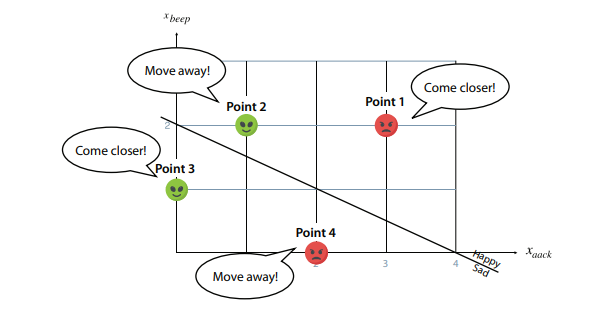

## **Introducción**

La regresión logística se utiliza para clasificar, lo usamos en machine learning para hacer clasificaciones binarias (2 clases) o multiclase (más de una clase).

## **Variables del dataset**

Los datos están disponibles en este link: https://github.com/rfordatascience/tidytuesday/blob/master/data/2021/2021-05-04/readme.md

Se ofrece una descripción del dataset además de detallarse los pasos de limpieza que se realizan a la base de datos original. Para una descripción del problema visitar https://www.waterpointdata.org/  

**La variable a predecir es status_id** y nos dice si hay o no disponibles agua, según diferentes variables.

Estas variables son:

* row_id: id

* lat_deg: latitud

* lon_deg: longitud

* report_date: fecha en que se reporto esa fuente de agua.

* status_id: identifica si está disponible esa fuente de agua, el dia de la visita (si/no).
* water_source_clean: describe la fuente de agua (variable categórica)

* water_tech: describe si el sistema utilizado para transportar el agua desde la fuente al punto de recolección (incluye la posibilidad de q sea un distribuidor).

* facility_type:

* country_name: pais

* install_year: año de la instalación

* installer: instalador

* pago: como se realiza el pago.

* status: estado de la condición física / mecánica del punto de agua.

In [ ]:
## Cargamos paquetes

install.packages(c("tidymodels", "themis", "doParallel"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘shape’, ‘future.apply’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘listenv’, ‘parallelly’, ‘splitfngr’, ‘prodlim’, ‘future’, ‘warp’, ‘mixopt’, ‘numDeriv’, ‘lbfgs’, ‘RcppArmadillo’, ‘DiceDesign’, ‘sfd’, ‘sparsevctrs’, ‘patchwork’, ‘globals’, ‘clock’, ‘ipred’, ‘timeDate’, ‘furrr’, ‘slider’, ‘GauPro’, ‘modelenv’, ‘dials’, ‘hardhat’, ‘infer’, ‘modeldata’, ‘parsnip’, ‘recipes’, ‘rsample’, ‘tailor’, ‘tune’, ‘workflows’, ‘workflowsets’, ‘yardstick’, ‘gower’, ‘RANN’, ‘ROSE’, ‘foreach’, ‘iterators’




In [ ]:
# cargamos librerias
library(tidymodels)
library(tidyverse)
library(themis)

── Attaching packages ────────────────────────────────────── tidymodels 1.5.0 ──

✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ purrr::discard() masks scales::discard()
✖ dplyr::filter()  masks stats::filter()
✖ dplyr::lag()     masks stats::lag()
✖ recipes::step()  masks stats::step()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ lubridate 1.9.5     ✔ tibble    3.3.1
✔ readr     2.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() mas

## **Cargar datos**

In [ ]:
## Ingreso el dataset

water_raw <- read_csv("https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2021/2021-05-04/water.csv")


Rows: 473293 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (9): report_date, status_id, water_source, water_tech, facility_type, co...
dbl (4): row_id, lat_deg, lon_deg, install_year

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## **Gráfico exploratorio**

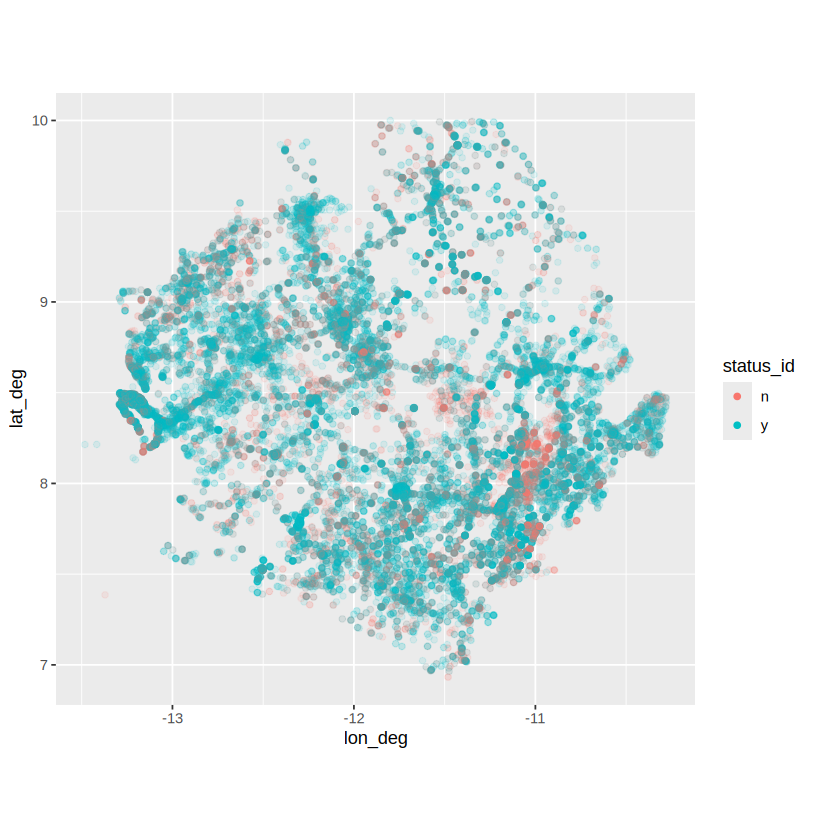

In [ ]:
water_raw %>%
  filter(
    country_name == "Sierra Leone",
    lat_deg > 0, lat_deg < 15, lon_deg < 0,
    status_id %in% c("y", "n")
  ) %>%
  ggplot(aes(lon_deg, lat_deg, color = status_id)) +
  geom_point(alpha = 0.1) +
  coord_fixed() +
  guides(color = guide_legend(override.aes = list(alpha = 1)))

## **Limpieza**

In [ ]:
water <- water_raw %>% #creamos nuevo objeto llamado water
  filter(
    country_name == "Sierra Leone",
    lat_deg > 0, lat_deg < 15, lon_deg < 0,
    status_id %in% c("y", "n")
  ) %>%
  mutate(pay = case_when(
    str_detect(pay, "^No") ~ "no",
    str_detect(pay, "^Yes") ~ "yes",
    is.na(pay) ~ pay,
    TRUE ~ "it's complicated"
  )) %>%
  select(-country_name, -status, -report_date) %>%
  mutate_if(is.character, as.factor)

water %>% glimpse()
water %>% count(status_id) # distribución clase target

Rows: 54,793
Columns: 10
$ row_id        <dbl> 252544, 36202, 34613, 36006, 36063, 36291, 34364, 34977,…
$ lat_deg       <dbl> 9.445763, 8.369090, 8.483420, 8.378530, 8.483860, 8.3853…
$ lon_deg       <dbl> -12.48694, -13.23060, -13.23500, -13.24050, -13.24310, -…
$ status_id     <fct> n, y, y, y, n, n, y, y, y, y, y, y, y, n, y, n, y, y, y,…
$ water_source  <fct> NA, NA, Surface Water (River/Stream/Lake/Pond/Dam), NA, …
$ water_tech    <fct> Hand Pump, Rope and Bucket, Hydram, Hydram, Hand Pump - …
$ facility_type <fct> NA, NA, No facilities, NA, NA, NA, Improved, Unimproved,…
$ install_year  <dbl> 1997, 2017, 2011, 2014, 1994, 2017, NA, 2003, 2017, 2016…
$ installer     <fct> NA, "Community", "Guma", "no", "private owner", "Communi…
$ pay           <fct> NA, yes, yes, yes, yes, yes, NA, yes, yes, yes, yes, yes…


status_id,n
<fct>,<int>
n,13773
y,41020


## **División train/test y folds**

In [ ]:
set.seed(123)
water_split <- initial_split(water, strata = status_id)
water_train <- training(water_split)
water_test <- testing(water_split)

set.seed(234)
water_folds <- vfold_cv(water_train, strata = status_id)


In [ ]:
water_train %>% count(status_id)
water_test %>% count(status_id)

status_id,n
<fct>,<int>
n,10329
y,30765


status_id,n
<fct>,<int>
n,3444
y,10255


## **La receta**

In [ ]:
logistic_recipe <-
  recipe(formula = status_id ~ ., data = water_train) %>% # status_id en función de todo lo demás
  update_role(row_id, new_role = "id") %>% # cambio del rol a id: el modelo no lo usa.
  step_unknown(all_nominal_predictors()) %>% # En variables categóricas predictoras reemplaza los NA por "unknown".
  step_other(all_nominal_predictors(), threshold = 0.03) %>% # Las categorías que aparecen en menos del 3% de las filas se agrupan en una sola llamada "other".
  step_impute_linear(install_year) %>% # install_year tiene faltantes. Se completan con una RL que predice el año a partir de los otros predictores.
  step_downsample(status_id) # balancea las clases eliminando filas al azar de la clase mayoritaria hasta igualar a la minoritaria

## **El modelo**

In [ ]:
logistic_spec <- logistic_reg() %>%
  set_mode("classification")

## **Workflow**

In [ ]:
log_workflow <- workflow() %>%
  add_recipe(logistic_recipe) %>%
  add_model(logistic_spec)

log_workflow

══ Workflow ════════════════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: logistic_reg()

── Preprocessor ────────────────────────────────────────────────────────────────
4 Recipe Steps

• step_unknown()
• step_other()
• step_impute_linear()
• step_downsample()

── Model ───────────────────────────────────────────────────────────────────────
Logistic Regression Model Specification (classification)

Computational engine: glm 


## **Entrenamiento con validación cruzada**

In [ ]:
doParallel::registerDoParallel()
set.seed(7443)
logistic_rs <-
  fit_resamples(log_workflow,
    resamples = water_folds,
    control = control_resamples(save_pred = TRUE)
  )

→ A | warning: prediction from rank-deficient fit; attr(*, "non-estim") has doubtful cases

There were issues with some computations   A: x2

There were issues with some computations   A: x2





## **Métricas de validación cruzada**

In [ ]:
logistic_rs %>%
  collect_metrics()

.metric,.estimator,mean,n,std_err,.config
<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
accuracy,binary,0.8744826,10,0.0016323334,pre0_mod0_post0
brier_class,binary,0.1050431,10,0.0009011271,pre0_mod0_post0
roc_auc,binary,0.9060314,10,0.0025528829,pre0_mod0_post0


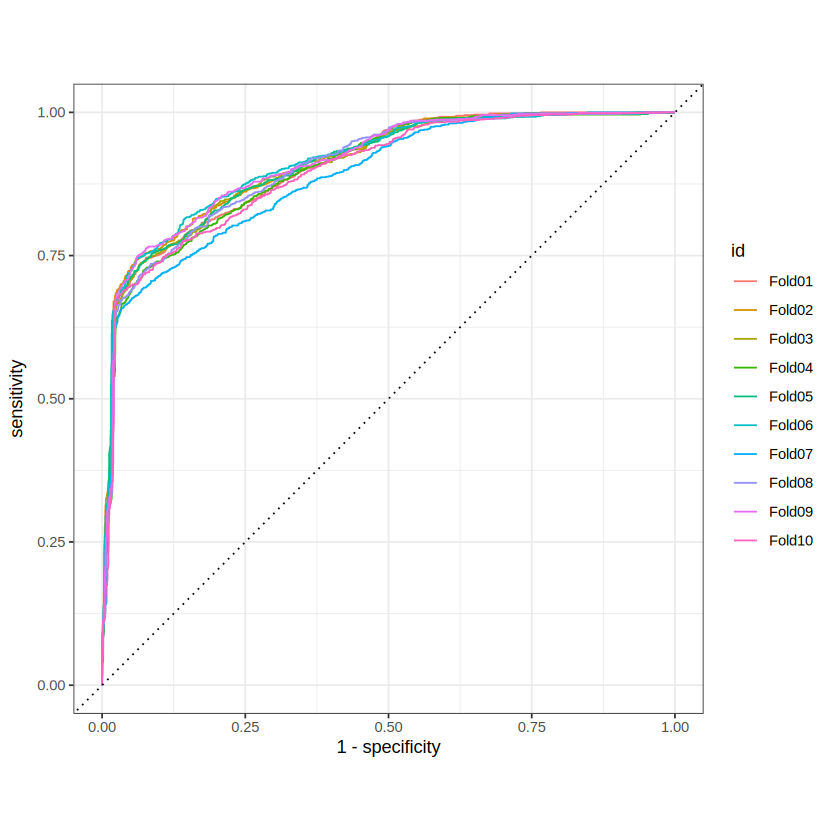

In [ ]:
collect_predictions(logistic_rs) %>%
  group_by(id) %>%
  roc_curve(status_id, .pred_n) %>%
  autoplot()

## **Ajuste final y evaluación en test**

In [ ]:
final_fitted <- last_fit(log_workflow, water_split)


## **Métricas en test**

In [ ]:
final_fitted %>%
  collect_metrics()

.metric,.estimator,.estimate,.config
<chr>,<chr>,<dbl>,<chr>
accuracy,binary,0.8728374,pre0_mod0_post0
roc_auc,binary,0.9055205,pre0_mod0_post0
brier_class,binary,0.1052733,pre0_mod0_post0


## **Predicciones**

In [ ]:
final_fitted %>%
  collect_predictions()

.pred_class,.pred_n,.pred_y,id,status_id,.row,.config
<fct>,<dbl>,<dbl>,<chr>,<fct>,<int>,<chr>
y,0.017263048,0.98273695,train/test split,y,2,pre0_mod0_post0
y,0.132491778,0.86750822,train/test split,y,4,pre0_mod0_post0
y,0.010066425,0.98993358,train/test split,y,8,pre0_mod0_post0
y,0.029327687,0.97067231,train/test split,y,10,pre0_mod0_post0
y,0.005617768,0.99438223,train/test split,y,11,pre0_mod0_post0
y,0.098865605,0.90113440,train/test split,y,12,pre0_mod0_post0
y,0.152077020,0.84792298,train/test split,y,13,pre0_mod0_post0
y,0.105264562,0.89473544,train/test split,n,14,pre0_mod0_post0
y,0.129679624,0.87032038,train/test split,y,17,pre0_mod0_post0


## **Matriz de confusión**

In [ ]:
final_fitted %>%
  collect_predictions() %>%
  conf_mat(status_id, .pred_class)

          Truth
Prediction    n    y
         n 2561  859
         y  883 9396